# 02 · CoolData value distribution

**Question:** which designs are physically implausible, and which normalization maps the remaining data to [-1, 1]
without being dominated by extremes?

**Answer:**

1. 310 of 56916 designs (0.5 %) break a simple plausibility rule, 33 of them entirely. They are excluded as diverged
   simulations, which removes the implausible extremes a global min-max range would include.
2. k and ε go on a log10 scale, they span 8 to 10 decades even without the excluded designs.
3. Every channel is normalized by quantiles of the curated designs: q0.001 → -1 and q0.999 → 1, nothing clipped.
   That balances resolution of the bulk against how far the rare peaks reach.

Source: [`experiments/01_cooldata-value-distribution`](../experiments/01_cooldata-value-distribution), a sweep over the
fluid voxels of every design at 800x160x32, the training grid: 2048-bin histograms and exact min, max, mean and std per
design and channel.

In [1]:
%matplotlib inline
from IPython.display import Markdown, display
from matplotlib.colors import LogNorm
import matplotlib.pyplot as plt
import numpy as np
import polars as pl
import pyvista as pv
import torch

from coolfrog.engine.cooldata import CoolData, CoolMetadata
from coolfrog.experiments import value_distribution as sweep  # binning, outlier rule and quantile helpers of the sweep
from coolfrog.lib import plots
from coolfrog.lib.config import HOST_CONFIG, DataConfig, Grid
from coolfrog.lib.datatypes import CHANNELS, Channel, NormalizationStats
from coolfrog.lib.experiment import PATH_EXPERIMENTS, markdown_table

PATH_RESULTS = PATH_EXPERIMENTS / "01_cooldata-value-distribution" / "results"
design_stats = pl.read_parquet(PATH_RESULTS / "design_stats.parquet")
histograms = np.load(PATH_RESULTS / "histograms.npz")
excluded = pl.read_csv(PATH_RESULTS / "excluded_designs.csv")
stats = NormalizationStats.load(PATH_RESULTS / "normalization_stats.csv")

design_id, counts = histograms["design_id"], histograms["counts"]  # (D,), (D, C, N_BINS)
is_excluded = np.isin(design_id, excluded["design_id"].to_numpy())
counts_all = counts.sum(0, dtype=np.int64)  # (C, N_BINS)
counts_curated = counts[~is_excluded].sum(0, dtype=np.int64)
CHANNEL_NAMES = [channel.value for channel in CHANNELS]
SYMBOLS = dict(zip(CHANNEL_NAMES, plots.CHANNEL_SYMBOLS, strict=True))  # `p [Pa]` -> `p`, the channels of the plots
SIGNED_CHANNELS = CHANNELS[:4]  # velocities and p, extremes by max |value|
RULE_LIMITS = {channel: sweep.MAX_VELOCITY for channel in CHANNELS[:3]} | {Channel.TEMPERATURE: sweep.TEMPERATURE_RANGE[1]}
channel_axes = pl.DataFrame(  # x and y axes of the plots follow the sweep's bins: linear within `scale` of `offset`
    {
        "channel": plots.CHANNEL_SYMBOLS,
        "offset": [sweep.BINNING[channel][0] for channel in CHANNELS],
        "linear_width": [sweep.BINNING[channel][1] for channel in CHANNELS],
        "rule_limit": [RULE_LIMITS.get(channel) for channel in CHANNELS],
        "is_signed": [channel in SIGNED_CHANNELS for channel in CHANNELS],
        "is_log": [channel in sweep.LOG_CHANNELS for channel in CHANNELS],
    },
    schema=plots.CHANNEL_AXES_SCHEMA,
)
plt.rcParams.update(plots.STYLE | {"figure.dpi": 110})
print(f"{len(design_id)} designs, {is_excluded.sum()} excluded, {(~is_excluded).sum()} curated")

56916 designs, 310 excluded, 56606 curated


## 1. Value ranges

Quantiles over the fluid voxels of all designs, and q0.9999 once the 310 excluded designs are removed. The extremes
sit far out in the tails: T reaches 3524 K at q0.9999 of all voxels, but only 344 K without the excluded designs.

In [2]:
QUANTILES = (1e-4, 0.5, 0.9999)
quantiles_all = sweep.histogram_quantiles(counts_all, QUANTILES)
quantiles_curated = sweep.histogram_quantiles(counts_curated, QUANTILES)
maximum = design_stats.group_by("channel", maintain_order=True).agg(pl.col("max").max())["max"].to_numpy()
value_ranges = pl.DataFrame(
    {
        "channel": CHANNEL_NAMES,
        "q0.0001": quantiles_all[:, 0],
        "median": quantiles_all[:, 1],
        "q0.9999": quantiles_all[:, 2],
        "max": maximum,
        "q0.9999 curated": quantiles_curated[:, 2],
    }
)
display(Markdown(markdown_table(value_ranges, significant_digits=4)))

| channel   | q0.0001   | median     | q0.9999   | max       | q0.9999 curated |
|-----------|-----------|------------|-----------|-----------|-----------------|
| Vx [m/s]  | -10.59    | 2.531      | 52.5      | 1400      | 44.93           |
| Vy [m/s]  | -12.91    | -7.084e-05 | 12.73     | 3960      | 10.74           |
| Vz [m/s]  | -5.214    | -0.000638  | 9.19      | 8576      | 8.684           |
| p [Pa]    | -889.5    | 0.008116   | 2767      | 5.515e+08 | 2465            |
| T [K]     | 293.1     | 295.5      | 3524      | 5000      | 344             |
| k [m²/s²] | 5.098e-07 | 0.1352     | 187.7     | 2.323e+07 | 72.37           |
| ε [m²/s³] | 5.553e-05 | 9.755      | 5.439e+05 | 4.352e+13 | 2.463e+05       |

## 2. Finding implausible designs

Each curve sorts one statistic per design in descending order: at rank r, r designs exceed it. A spike at the left
means a few designs lie far off the rest.

- Only the max spikes: a few bad voxels in a design
- q0.999 spikes too: a region of at least 0.1 % of the fluid
- The median spikes too: the whole design

Dashed lines: the outlier rule. A design is excluded when any velocity component exceeds 100 m/s or T leaves 250 to
600 K, generous bounds next to inlet speeds of 1 to 7 m/s and bodies of at most 353 K.

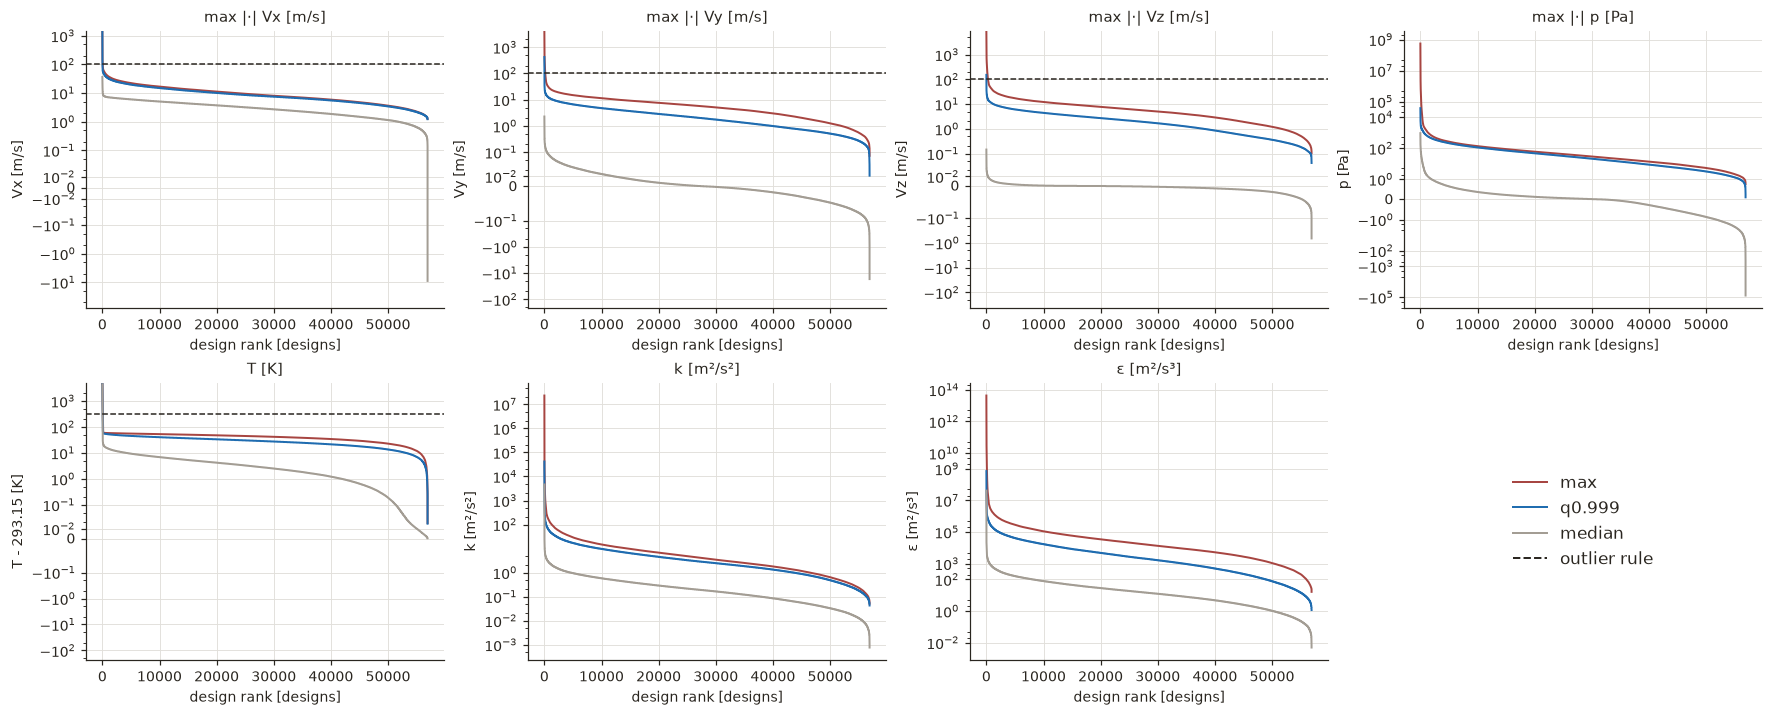

In [3]:
signed = pl.col("channel").is_in([channel.value for channel in SIGNED_CHANNELS])
designs = design_stats.select(
    pl.col("channel").replace_strict(SYMBOLS),
    pl.when(signed).then(pl.max_horizontal(pl.col("max"), -pl.col("min"))).otherwise(pl.col("max")).alias("extreme"),
    "q0.999",
    pl.col("q0.5").alias("median"),
)
plots.design_extremes(designs, channel_axes)

## 3. Excluded designs

33 designs fail entirely (T median 630 to 4701 K), the other 277 locally: half of them in under 0.008 % of their fluid,
only 13 in more than 1 %. 15 designs reach exactly 100 K or 5000 K, likely the solver's temperature clamps.
13 local failures also run hot overall, with T medians of 357 to 572 K above the 353 K the hottest
body allows. All 26 designs excluded by the earlier 10 % sweep at 1600x320x64 are excluded here too.

In [4]:
def share_breaking_rule(design_counts: np.ndarray) -> np.ndarray:
    """(D, C, N_BINS) counts -> (D,) share of fluid voxels whose channel breaks the outlier rule, max over channels."""
    centers = sweep.BIN_CENTERS
    breaks = np.zeros_like(centers, dtype=bool)
    breaks[:3] = np.abs(centers[:3]) > sweep.MAX_VELOCITY
    temperature = CHANNELS.index(Channel.TEMPERATURE)
    breaks[temperature] = (centers[temperature] < sweep.TEMPERATURE_RANGE[0]) | (centers[temperature] > sweep.TEMPERATURE_RANGE[1])
    return ((design_counts * breaks).sum(-1) / design_counts.sum(-1)).max(-1)


temperature_median = design_stats.filter(pl.col("channel") == Channel.TEMPERATURE.value).select("design_id", pl.col("q0.5").alias("T median [K]"))
outliers = (
    pl.DataFrame({"design_id": design_id[is_excluded], "rule-breaking voxels [%]": 100 * share_breaking_rule(counts[is_excluded])})
    .join(excluded, on="design_id")
    .join(temperature_median, on="design_id")
    .with_columns(pl.when(pl.col("rule-breaking voxels [%]") > 50).then(pl.lit("whole design")).otherwise(pl.lit("local")).alias("failure"))
    .sort("rule-breaking voxels [%]", descending=True)
    .select("design_id", "failure", "rule-breaking voxels [%]", "T median [K]", "reason")
)
display(Markdown(markdown_table(outliers, significant_digits=4)))

| design_id | failure      | rule-breaking voxels [%] | T median [K] | reason                                                      |
|-----------|--------------|--------------------------|--------------|-------------------------------------------------------------|
| 178876    | whole design | 99.92                    | 4540         | \|V\| 6193 > 100 m/s, T min 100 < 250 K, T max 5000 > 600 K |
| 128001    | whole design | 99.64                    | 3774         | \|V\| 1682 > 100 m/s, T min 139 < 250 K, T max 4015 > 600 K |
| 243826    | whole design | 99.64                    | 3862         | \|V\| 2811 > 100 m/s, T min 214 < 250 K, T max 4055 > 600 K |
| 20212     | whole design | 99.62                    | 4385         | \|V\| 4186 > 100 m/s, T min 181 < 250 K, T max 5000 > 600 K |
| 183822    | whole design | 99.51                    | 4701         | \|V\| 1400 > 100 m/s, T min 185 < 250 K, T max 5000 > 600 K |
| 217352    | whole design | 98.85                    | 4138         | \|V\| 1469 > 100 m/s, T min 100 < 250 K, T max 4325 > 600 K |
| 188769    | whole design | 98.82                    | 3292         | \|V\| 3609 > 100 m/s, T min 100 < 250 K, T max 5000 > 600 K |
| 224604    | whole design | 98.13                    | 2333         | \|V\| 3373 > 100 m/s, T min 100 < 250 K, T max 5000 > 600 K |
| 26477     | whole design | 98.09                    | 3367         | \|V\| 3691 > 100 m/s, T min 249 < 250 K, T max 5000 > 600 K |
| 223794    | whole design | 97.97                    | 2844         | \|V\| 816 > 100 m/s, T min 244 < 250 K, T max 3402 > 600 K  |
| 245751    | whole design | 97.51                    | 2234         | \|V\| 1255 > 100 m/s, T max 2386 > 600 K                    |
| 208773    | whole design | 96.35                    | 1225         | \|V\| 1807 > 100 m/s, T min 121 < 250 K, T max 2807 > 600 K |
| 187076    | whole design | 96.1                     | 3076         | \|V\| 1123 > 100 m/s, T max 3446 > 600 K                    |
| 269766    | whole design | 95.93                    | 2283         | \|V\| 570 > 100 m/s, T max 2359 > 600 K                     |
| 127546    | whole design | 93.44                    | 2163         | \|V\| 4322 > 100 m/s, T min 115 < 250 K, T max 5000 > 600 K |
| 197826    | whole design | 93.01                    | 1715         | \|V\| 1546 > 100 m/s, T max 2038 > 600 K                    |
| 193762    | whole design | 92.92                    | 2028         | \|V\| 1474 > 100 m/s, T max 2561 > 600 K                    |
| 241009    | whole design | 90.4                     | 1924         | \|V\| 1316 > 100 m/s, T max 2173 > 600 K                    |
| 39414     | whole design | 90.24                    | 2258         | \|V\| 122 > 100 m/s, T max 2876 > 600 K                     |
| 146027    | whole design | 90.09                    | 3008         | \|V\| 1567 > 100 m/s, T max 3553 > 600 K                    |
| 201586    | whole design | 86.85                    | 3008         | \|V\| 106 > 100 m/s, T max 3433 > 600 K                     |
| 244565    | whole design | 85.66                    | 1106         | \|V\| 909 > 100 m/s, T max 1254 > 600 K                     |
| 35267     | whole design | 83.46                    | 911.6        | \|V\| 1206 > 100 m/s, T min 230 < 250 K, T max 1310 > 600 K |
| 35426     | whole design | 82.36                    | 1807         | \|V\| 1305 > 100 m/s, T max 2313 > 600 K                    |
| 257766    | whole design | 78.55                    | 839.3        | \|V\| 438 > 100 m/s, T max 947 > 600 K                      |
| 255099    | whole design | 78.49                    | 984.8        | \|V\| 436 > 100 m/s, T max 1280 > 600 K                     |
| 37502     | whole design | 76.25                    | 825.9        | \|V\| 934 > 100 m/s, T max 1058 > 600 K                     |
| 256318    | whole design | 73.23                    | 943.1        | \|V\| 532 > 100 m/s, T max 1119 > 600 K                     |
| 259780    | whole design | 71.28                    | 1698         | T max 3055 > 600 K                                          |
| 249054    | whole design | 70.47                    | 1214         | \|V\| 716 > 100 m/s, T max 1801 > 600 K                     |
| 21212     | whole design | 66.6                     | 1788         | \|V\| 470 > 100 m/s, T max 2245 > 600 K                     |
| 218060    | whole design | 56.01                    | 819.3        | \|V\| 147 > 100 m/s, T max 1493 > 600 K                     |
| 216040    | whole design | 51.84                    | 629.5        | \|V\| 707 > 100 m/s, T max 1348 > 600 K                     |
| 198098    | local        | 38.15                    | 572.3        | \|V\| 582 > 100 m/s, T max 5000 > 600 K                     |
| 222867    | local        | 36.43                    | 432.3        | \|V\| 691 > 100 m/s, T max 1023 > 600 K                     |
| 34061     | local        | 25.27                    | 432.3        | \|V\| 1480 > 100 m/s, T max 3994 > 600 K                    |
| 36214     | local        | 17.28                    | 295.4        | \|V\| 106 > 100 m/s, T max 956 > 600 K                      |
| 143066    | local        | 15.34                    | 298.6        | \|V\| 7449 > 100 m/s, T min 100 < 250 K, T max 5000 > 600 K |
| 23813     | local        | 12.11                    | 298.2        | \|V\| 145 > 100 m/s                                         |
| 224016    | local        | 7.904                    | 311.7        | \|V\| 713 > 100 m/s, T max 624 > 600 K                      |
| 2248      | local        | 7.795                    | 311          | \|V\| 161 > 100 m/s                                         |
| 207598    | local        | 5.481                    | 297.5        | \|V\| 141 > 100 m/s                                         |
| 258251    | local        | 4.777                    | 294.4        | \|V\| 132 > 100 m/s                                         |
| 199793    | local        | 4.429                    | 296.3        | \|V\| 127 > 100 m/s                                         |
| 189155    | local        | 3.572                    | 297.2        | \|V\| 130 > 100 m/s                                         |
| 7219      | local        | 2.953                    | 296.2        | \|V\| 116 > 100 m/s                                         |
| 174805    | local        | 0.8455                   | 487.8        | \|V\| 453 > 100 m/s, T max 605 > 600 K                      |
| 246021    | local        | 0.6004                   | 317          | \|V\| 8576 > 100 m/s, T max 5000 > 600 K                    |
| 188623    | local        | 0.4454                   | 313.7        | \|V\| 132 > 100 m/s, T max 619 > 600 K                      |
| 221260    | local        | 0.4069                   | 298.5        | \|V\| 3002 > 100 m/s, T max 5000 > 600 K                    |
| 29214     | local        | 0.3454                   | 375.7        | \|V\| 2104 > 100 m/s, T max 5000 > 600 K                    |
| 212827    | local        | 0.2827                   | 306.4        | \|V\| 112 > 100 m/s                                         |
| 246557    | local        | 0.1582                   | 351.4        | \|V\| 661 > 100 m/s, T min 100 < 250 K                      |
| 217042    | local        | 0.1002                   | 366.1        | \|V\| 483 > 100 m/s                                         |
| 221052    | local        | 0.09263                  | 319.8        | \|V\| 386 > 100 m/s                                         |
| 181792    | local        | 0.09135                  | 368.8        | \|V\| 688 > 100 m/s, T max 946 > 600 K                      |
| 254091    | local        | 0.08818                  | 340.9        | \|V\| 543 > 100 m/s, T max 641 > 600 K                      |
| 142808    | local        | 0.08633                  | 352.9        | \|V\| 559 > 100 m/s                                         |
| 172817    | local        | 0.07931                  | 377.8        | \|V\| 557 > 100 m/s                                         |
| 190830    | local        | 0.06461                  | 317.9        | \|V\| 283 > 100 m/s                                         |
| 17453     | local        | 0.06445                  | 349.3        | \|V\| 707 > 100 m/s, T max 683 > 600 K                      |
| 180345    | local        | 0.06397                  | 365.2        | \|V\| 673 > 100 m/s, T max 647 > 600 K                      |
| 10839     | local        | 0.06085                  | 334.8        | \|V\| 369 > 100 m/s                                         |
| 233764    | local        | 0.05853                  | 320.8        | \|V\| 294 > 100 m/s                                         |
| 14809     | local        | 0.0536                   | 323.3        | \|V\| 412 > 100 m/s                                         |
| 252345    | local        | 0.05332                  | 335.3        | \|V\| 299 > 100 m/s                                         |
| 222009    | local        | 0.04907                  | 334.3        | \|V\| 440 > 100 m/s                                         |
| 7632      | local        | 0.04893                  | 352.2        | \|V\| 451 > 100 m/s                                         |
| 206798    | local        | 0.04801                  | 397.7        | \|V\| 541 > 100 m/s, T max 1507 > 600 K                     |
| 4440      | local        | 0.04801                  | 427.2        | \|V\| 617 > 100 m/s, T max 873 > 600 K                      |
| 229602    | local        | 0.04752                  | 339.2        | \|V\| 477 > 100 m/s, T max 606 > 600 K                      |
| 137806    | local        | 0.04748                  | 316.1        | \|V\| 308 > 100 m/s                                         |
| 133813    | local        | 0.04658                  | 327.3        | \|V\| 414 > 100 m/s                                         |
| 218267    | local        | 0.04643                  | 322.2        | \|V\| 331 > 100 m/s                                         |
| 236352    | local        | 0.04538                  | 307.5        | \|V\| 383 > 100 m/s                                         |
| 233508    | local        | 0.04411                  | 334.8        | \|V\| 448 > 100 m/s                                         |
| 213316    | local        | 0.04107                  | 325.2        | \|V\| 533 > 100 m/s, T max 1421 > 600 K                     |
| 262009    | local        | 0.04032                  | 351.4        | \|V\| 289 > 100 m/s                                         |
| 132059    | local        | 0.0401                   | 295          | \|V\| 103 > 100 m/s                                         |
| 244777    | local        | 0.03902                  | 323.3        | \|V\| 329 > 100 m/s                                         |
| 11217     | local        | 0.03828                  | 331.8        | \|V\| 533 > 100 m/s                                         |
| 179008    | local        | 0.03789                  | 321.8        | \|V\| 510 > 100 m/s, T max 695 > 600 K                      |
| 173287    | local        | 0.03583                  | 308.8        | \|V\| 260 > 100 m/s                                         |
| 209076    | local        | 0.03531                  | 328.6        | \|V\| 344 > 100 m/s                                         |
| 200846    | local        | 0.03467                  | 322.2        | \|V\| 234 > 100 m/s                                         |
| 185542    | local        | 0.03405                  | 321.5        | \|V\| 315 > 100 m/s                                         |
| 255256    | local        | 0.03397                  | 299.7        | \|V\| 181 > 100 m/s                                         |
| 220515    | local        | 0.03071                  | 342.7        | \|V\| 441 > 100 m/s                                         |
| 17207     | local        | 0.03065                  | 306.4        | \|V\| 182 > 100 m/s                                         |
| 205278    | local        | 0.03038                  | 320.5        | \|V\| 581 > 100 m/s, T max 623 > 600 K                      |
| 201631    | local        | 0.03032                  | 312.4        | \|V\| 331 > 100 m/s                                         |
| 144097    | local        | 0.02858                  | 300.7        | \|V\| 136 > 100 m/s                                         |
| 6208      | local        | 0.02846                  | 305.8        | \|V\| 270 > 100 m/s                                         |
| 253078    | local        | 0.02843                  | 307.6        | \|V\| 142 > 100 m/s                                         |
| 16612     | local        | 0.02843                  | 304.3        | \|V\| 166 > 100 m/s                                         |
| 24899     | local        | 0.02833                  | 304.4        | \|V\| 151 > 100 m/s                                         |
| 237038    | local        | 0.02816                  | 310          | \|V\| 269 > 100 m/s                                         |
| 188613    | local        | 0.02693                  | 305.5        | \|V\| 209 > 100 m/s                                         |
| 257522    | local        | 0.02692                  | 310.4        | \|V\| 189 > 100 m/s                                         |
| 205504    | local        | 0.02691                  | 309.6        | \|V\| 165 > 100 m/s                                         |
| 11047     | local        | 0.02589                  | 303.4        | \|V\| 237 > 100 m/s                                         |
| 135513    | local        | 0.02513                  | 307.5        | \|V\| 278 > 100 m/s                                         |
| 195857    | local        | 0.02506                  | 310.8        | \|V\| 188 > 100 m/s                                         |
| 164301    | local        | 0.02487                  | 313.9        | \|V\| 376 > 100 m/s                                         |
| 252276    | local        | 0.02435                  | 300          | \|V\| 191 > 100 m/s                                         |
| 246568    | local        | 0.02432                  | 312.7        | \|V\| 227 > 100 m/s                                         |
| 28918     | local        | 0.02354                  | 312.9        | \|V\| 360 > 100 m/s                                         |
| 139017    | local        | 0.02331                  | 312          | \|V\| 216 > 100 m/s                                         |
| 165774    | local        | 0.0229                   | 319.1        | \|V\| 525 > 100 m/s                                         |
| 192807    | local        | 0.0218                   | 295.8        | \|V\| 100 > 100 m/s                                         |
| 220290    | local        | 0.02134                  | 305          | \|V\| 317 > 100 m/s                                         |
| 229534    | local        | 0.02123                  | 304.6        | \|V\| 340 > 100 m/s                                         |
| 190847    | local        | 0.02093                  | 310.8        | \|V\| 273 > 100 m/s                                         |
| 207789    | local        | 0.02017                  | 302.6        | \|V\| 212 > 100 m/s                                         |
| 173252    | local        | 0.02007                  | 308.8        | \|V\| 168 > 100 m/s                                         |
| 144072    | local        | 0.01965                  | 356.7        | \|V\| 541 > 100 m/s, T max 2191 > 600 K                     |
| 25091     | local        | 0.01902                  | 306.3        | \|V\| 268 > 100 m/s                                         |
| 6897      | local        | 0.01841                  | 299.7        | \|V\| 248 > 100 m/s                                         |
| 204523    | local        | 0.01828                  | 308.6        | \|V\| 283 > 100 m/s                                         |
| 11285     | local        | 0.01824                  | 297.1        | \|V\| 254 > 100 m/s                                         |
| 207582    | local        | 0.01816                  | 309.6        | \|V\| 339 > 100 m/s                                         |
| 190522    | local        | 0.01815                  | 299.8        | \|V\| 152 > 100 m/s                                         |
| 146019    | local        | 0.01797                  | 307.3        | \|V\| 150 > 100 m/s                                         |
| 176857    | local        | 0.0179                   | 302          | \|V\| 175 > 100 m/s                                         |
| 265801    | local        | 0.01769                  | 302.5        | \|V\| 163 > 100 m/s                                         |
| 179611    | local        | 0.01743                  | 303.6        | \|V\| 194 > 100 m/s                                         |
| 33499     | local        | 0.01727                  | 303.3        | \|V\| 163 > 100 m/s                                         |
| 166006    | local        | 0.01714                  | 317.3        | \|V\| 532 > 100 m/s, T max 665 > 600 K                      |
| 161023    | local        | 0.01709                  | 324.1        | \|V\| 448 > 100 m/s, T max 781 > 600 K                      |
| 256802    | local        | 0.01681                  | 305.5        | \|V\| 213 > 100 m/s                                         |
| 265563    | local        | 0.01667                  | 300.2        | \|V\| 162 > 100 m/s                                         |
| 160327    | local        | 0.01654                  | 316.1        | \|V\| 152 > 100 m/s                                         |
| 10653     | local        | 0.0159                   | 303.5        | \|V\| 170 > 100 m/s                                         |
| 31255     | local        | 0.01587                  | 304          | \|V\| 331 > 100 m/s                                         |
| 186306    | local        | 0.01576                  | 307.1        | \|V\| 129 > 100 m/s                                         |
| 209760    | local        | 0.01534                  | 311.3        | \|V\| 126 > 100 m/s                                         |
| 17841     | local        | 0.01505                  | 302.8        | \|V\| 159 > 100 m/s                                         |
| 25208     | local        | 0.01483                  | 301          | \|V\| 187 > 100 m/s                                         |
| 10658     | local        | 0.01472                  | 342.1        | \|V\| 430 > 100 m/s, T max 643 > 600 K                      |
| 34855     | local        | 0.01466                  | 307.6        | \|V\| 931 > 100 m/s, T max 1434 > 600 K                     |
| 175826    | local        | 0.01424                  | 302.3        | \|V\| 283 > 100 m/s                                         |
| 206504    | local        | 0.01389                  | 303          | \|V\| 171 > 100 m/s                                         |
| 38434     | local        | 0.01373                  | 298.6        | \|V\| 177 > 100 m/s                                         |
| 254537    | local        | 0.01351                  | 295.9        | \|V\| 101 > 100 m/s                                         |
| 178561    | local        | 0.01336                  | 307.1        | \|V\| 314 > 100 m/s                                         |
| 244059    | local        | 0.01329                  | 299.5        | \|V\| 114 > 100 m/s                                         |
| 175286    | local        | 0.01326                  | 301.4        | \|V\| 179 > 100 m/s                                         |
| 28875     | local        | 0.01285                  | 294.7        | \|V\| 257 > 100 m/s                                         |
| 17074     | local        | 0.01277                  | 309.2        | \|V\| 383 > 100 m/s                                         |
| 167843    | local        | 0.01268                  | 305.2        | \|V\| 190 > 100 m/s                                         |
| 36713     | local        | 0.0124                   | 300.5        | \|V\| 126 > 100 m/s                                         |
| 23282     | local        | 0.01236                  | 298.8        | \|V\| 156 > 100 m/s                                         |
| 161315    | local        | 0.0123                   | 312.4        | \|V\| 129 > 100 m/s                                         |
| 139750    | local        | 0.01229                  | 302          | \|V\| 147 > 100 m/s                                         |
| 142341    | local        | 0.01201                  | 296.7        | \|V\| 147 > 100 m/s                                         |
| 142521    | local        | 0.01134                  | 297.1        | \|V\| 162 > 100 m/s                                         |
| 35315     | local        | 0.01103                  | 308.4        | \|V\| 221 > 100 m/s                                         |
| 9623      | local        | 0.0105                   | 310.6        | \|V\| 126 > 100 m/s                                         |
| 142313    | local        | 0.01029                  | 324.5        | \|V\| 515 > 100 m/s                                         |
| 12438     | local        | 0.01005                  | 302.6        | \|V\| 213 > 100 m/s                                         |
| 248056    | local        | 0.01003                  | 302.8        | \|V\| 104 > 100 m/s                                         |
| 164574    | local        | 0.009789                 | 301.6        | \|V\| 116 > 100 m/s                                         |
| 20837     | local        | 0.009785                 | 310.6        | \|V\| 391 > 100 m/s                                         |
| 168280    | local        | 0.009408                 | 300.6        | \|V\| 169 > 100 m/s                                         |
| 178322    | local        | 0.008944                 | 311.5        | \|V\| 144 > 100 m/s                                         |
| 250773    | local        | 0.008914                 | 318.5        | \|V\| 577 > 100 m/s, T max 773 > 600 K                      |
| 173290    | local        | 0.008546                 | 302.6        | \|V\| 143 > 100 m/s                                         |
| 239773    | local        | 0.008342                 | 298.9        | \|V\| 180 > 100 m/s                                         |
| 161068    | local        | 0.008298                 | 305.2        | \|V\| 115 > 100 m/s                                         |
| 246811    | local        | 0.008272                 | 300.3        | \|V\| 121 > 100 m/s                                         |
| 38667     | local        | 0.008264                 | 300.2        | \|V\| 446 > 100 m/s                                         |
| 161858    | local        | 0.007559                 | 308.4        | \|V\| 140 > 100 m/s                                         |
| 142532    | local        | 0.007553                 | 319.8        | \|V\| 168 > 100 m/s                                         |
| 14854     | local        | 0.007222                 | 300.8        | \|V\| 171 > 100 m/s                                         |
| 138787    | local        | 0.007129                 | 308.8        | \|V\| 212 > 100 m/s                                         |
| 236082    | local        | 0.00682                  | 295.7        | \|V\| 195 > 100 m/s                                         |
| 200058    | local        | 0.006344                 | 308.4        | \|V\| 142 > 100 m/s                                         |
| 33501     | local        | 0.006045                 | 308.8        | \|V\| 220 > 100 m/s                                         |
| 257851    | local        | 0.005922                 | 305          | \|V\| 238 > 100 m/s                                         |
| 11886     | local        | 0.00589                  | 301.5        | \|V\| 139 > 100 m/s                                         |
| 18091     | local        | 0.005623                 | 298.2        | \|V\| 211 > 100 m/s                                         |
| 170315    | local        | 0.00531                  | 299.8        | \|V\| 149 > 100 m/s                                         |
| 17281     | local        | 0.004774                 | 301.6        | \|V\| 129 > 100 m/s                                         |
| 164281    | local        | 0.0046                   | 302.9        | \|V\| 321 > 100 m/s                                         |
| 187314    | local        | 0.004596                 | 300.8        | \|V\| 474 > 100 m/s, T max 674 > 600 K                      |
| 188061    | local        | 0.004595                 | 298.4        | \|V\| 173 > 100 m/s                                         |
| 221581    | local        | 0.004534                 | 294.8        | \|V\| 215 > 100 m/s                                         |
| 208274    | local        | 0.004446                 | 301          | \|V\| 327 > 100 m/s                                         |
| 141574    | local        | 0.004184                 | 294.2        | \|V\| 132 > 100 m/s                                         |
| 181061    | local        | 0.004112                 | 297.8        | \|V\| 141 > 100 m/s                                         |
| 131522    | local        | 0.004098                 | 300.1        | \|V\| 105 > 100 m/s                                         |
| 165537    | local        | 0.003949                 | 297.7        | \|V\| 147 > 100 m/s                                         |
| 257259    | local        | 0.003893                 | 301          | \|V\| 106 > 100 m/s                                         |
| 261504    | local        | 0.00389                  | 296.6        | \|V\| 157 > 100 m/s                                         |
| 224750    | local        | 0.003872                 | 302          | \|V\| 201 > 100 m/s                                         |
| 173265    | local        | 0.003668                 | 298.4        | \|V\| 192 > 100 m/s                                         |
| 34607     | local        | 0.003617                 | 302.1        | \|V\| 108 > 100 m/s                                         |
| 242535    | local        | 0.003461                 | 306.3        | \|V\| 450 > 100 m/s                                         |
| 222759    | local        | 0.003164                 | 295.5        | \|V\| 164 > 100 m/s                                         |
| 149038    | local        | 0.003115                 | 296.8        | \|V\| 290 > 100 m/s                                         |
| 29663     | local        | 0.002911                 | 322.6        | \|V\| 940 > 100 m/s                                         |
| 269079    | local        | 0.002882                 | 297.8        | \|V\| 119 > 100 m/s                                         |
| 197510    | local        | 0.002834                 | 296.4        | \|V\| 180 > 100 m/s                                         |
| 137287    | local        | 0.002753                 | 304          | \|V\| 302 > 100 m/s                                         |
| 209578    | local        | 0.002729                 | 300.4        | \|V\| 115 > 100 m/s                                         |
| 224113    | local        | 0.002613                 | 300.9        | \|V\| 115 > 100 m/s                                         |
| 195566    | local        | 0.00253                  | 297.1        | \|V\| 118 > 100 m/s                                         |
| 270524    | local        | 0.002426                 | 296.4        | \|V\| 115 > 100 m/s                                         |
| 23433     | local        | 0.002416                 | 298.7        | \|V\| 147 > 100 m/s                                         |
| 259005    | local        | 0.002314                 | 296.4        | \|V\| 110 > 100 m/s                                         |
| 223519    | local        | 0.002239                 | 299.8        | \|V\| 103 > 100 m/s                                         |
| 12820     | local        | 0.002215                 | 299.3        | \|V\| 102 > 100 m/s                                         |
| 175042    | local        | 0.002088                 | 297.3        | \|V\| 255 > 100 m/s                                         |
| 10298     | local        | 0.002058                 | 297.8        | \|V\| 184 > 100 m/s                                         |
| 264788    | local        | 0.002024                 | 312.7        | \|V\| 357 > 100 m/s                                         |
| 29839     | local        | 0.001969                 | 305.2        | \|V\| 243 > 100 m/s                                         |
| 5423      | local        | 0.00192                  | 303.8        | \|V\| 104 > 100 m/s                                         |
| 144750    | local        | 0.001896                 | 295.1        | \|V\| 137 > 100 m/s                                         |
| 38701     | local        | 0.001883                 | 297.4        | \|V\| 107 > 100 m/s                                         |
| 225000    | local        | 0.001745                 | 298          | \|V\| 136 > 100 m/s                                         |
| 263067    | local        | 0.001732                 | 297.4        | \|V\| 134 > 100 m/s                                         |
| 193269    | local        | 0.001607                 | 309.8        | \|V\| 439 > 100 m/s                                         |
| 38004     | local        | 0.001567                 | 305.3        | \|V\| 113 > 100 m/s                                         |
| 12617     | local        | 0.001534                 | 299.2        | \|V\| 310 > 100 m/s                                         |
| 32022     | local        | 0.001433                 | 300.6        | \|V\| 102 > 100 m/s                                         |
| 268812    | local        | 0.001414                 | 295.7        | \|V\| 104 > 100 m/s                                         |
| 246567    | local        | 0.001345                 | 295.5        | \|V\| 116 > 100 m/s                                         |
| 24071     | local        | 0.001326                 | 306.9        | \|V\| 1884 > 100 m/s, T max 3186 > 600 K                    |
| 137751    | local        | 0.001294                 | 300.2        | \|V\| 170 > 100 m/s                                         |
| 33469     | local        | 0.001187                 | 306.9        | \|V\| 135 > 100 m/s                                         |
| 32865     | local        | 0.001116                 | 309          | \|V\| 137 > 100 m/s                                         |
| 239799    | local        | 0.001077                 | 298.1        | \|V\| 280 > 100 m/s                                         |
| 242362    | local        | 0.001064                 | 302          | \|V\| 102 > 100 m/s                                         |
| 28479     | local        | 0.001047                 | 305.3        | \|V\| 238 > 100 m/s                                         |
| 182813    | local        | 0.001047                 | 294          | \|V\| 110 > 100 m/s                                         |
| 7465      | local        | 0.001004                 | 296.1        | \|V\| 170 > 100 m/s                                         |
| 232099    | local        | 0.0009834                | 301.2        | \|V\| 221 > 100 m/s                                         |
| 172309    | local        | 0.0009808                | 296.2        | \|V\| 193 > 100 m/s                                         |
| 245801    | local        | 0.0009688                | 302.9        | \|V\| 301 > 100 m/s                                         |
| 264854    | local        | 0.0009632                | 316.7        | \|V\| 1154 > 100 m/s, T max 1422 > 600 K                    |
| 168047    | local        | 0.0009586                | 312.7        | \|V\| 984 > 100 m/s, T max 1576 > 600 K                     |
| 204007    | local        | 0.0009336                | 296.1        | \|V\| 119 > 100 m/s                                         |
| 24810     | local        | 0.0009225                | 302.6        | \|V\| 355 > 100 m/s                                         |
| 216344    | local        | 0.0009122                | 302.2        | \|V\| 607 > 100 m/s, T max 605 > 600 K                      |
| 159501    | local        | 0.0009092                | 298.9        | \|V\| 214 > 100 m/s                                         |
| 245536    | local        | 0.000893                 | 298.4        | \|V\| 289 > 100 m/s                                         |
| 254280    | local        | 0.0008849                | 299.1        | \|V\| 102 > 100 m/s                                         |
| 39418     | local        | 0.0008811                | 298.8        | \|V\| 161 > 100 m/s                                         |
| 33245     | local        | 0.0007891                | 305.3        | \|V\| 958 > 100 m/s, T max 1737 > 600 K                     |
| 136148    | local        | 0.000789                 | 308.8        | \|V\| 375 > 100 m/s                                         |
| 221072    | local        | 0.0007534                | 308.4        | \|V\| 490 > 100 m/s                                         |
| 178816    | local        | 0.0007495                | 297          | \|V\| 157 > 100 m/s                                         |
| 4241      | local        | 0.0007483                | 300          | \|V\| 304 > 100 m/s                                         |
| 198100    | local        | 0.0007253                | 297.7        | \|V\| 105 > 100 m/s                                         |
| 17089     | local        | 0.0007075                | 297.8        | \|V\| 176 > 100 m/s                                         |
| 20680     | local        | 0.0006995                | 304          | \|V\| 138 > 100 m/s                                         |
| 135319    | local        | 0.0006982                | 310.4        | \|V\| 562 > 100 m/s                                         |
| 251110    | local        | 0.0006882                | 294.8        | \|V\| 1141 > 100 m/s, T max 1405 > 600 K                    |
| 177612    | local        | 0.0006818                | 294.1        | \|V\| 458 > 100 m/s                                         |
| 224843    | local        | 0.0006759                | 304.6        | \|V\| 283 > 100 m/s                                         |
| 259281    | local        | 0.0006717                | 295.5        | \|V\| 125 > 100 m/s                                         |
| 174807    | local        | 0.0006657                | 299.9        | \|V\| 929 > 100 m/s, T max 970 > 600 K                      |
| 189034    | local        | 0.0006652                | 296.6        | \|V\| 185 > 100 m/s                                         |
| 247355    | local        | 0.0006625                | 302.4        | \|V\| 172 > 100 m/s                                         |
| 4059      | local        | 0.0006567                | 300.8        | \|V\| 145 > 100 m/s                                         |
| 13258     | local        | 0.0006403                | 294.9        | \|V\| 192 > 100 m/s                                         |
| 160312    | local        | 0.0005989                | 295.4        | \|V\| 311 > 100 m/s                                         |
| 260501    | local        | 0.000591                 | 296.5        | \|V\| 198 > 100 m/s                                         |
| 268355    | local        | 0.0005802                | 294.3        | \|V\| 151 > 100 m/s                                         |
| 184039    | local        | 0.0005727                | 301.1        | \|V\| 103 > 100 m/s                                         |
| 128038    | local        | 0.0005717                | 297.1        | \|V\| 105 > 100 m/s                                         |
| 125777    | local        | 0.0005672                | 301.3        | \|V\| 134 > 100 m/s                                         |
| 181337    | local        | 0.0005624                | 298.1        | \|V\| 274 > 100 m/s                                         |
| 226081    | local        | 0.0005586                | 302.3        | \|V\| 323 > 100 m/s                                         |
| 219784    | local        | 0.0005197                | 296.2        | \|V\| 142 > 100 m/s                                         |
| 8268      | local        | 0.0005039                | 298.2        | \|V\| 220 > 100 m/s                                         |
| 189006    | local        | 0.0004947                | 301.6        | \|V\| 513 > 100 m/s                                         |
| 10901     | local        | 0.0004805                | 296.2        | \|V\| 301 > 100 m/s                                         |
| 23839     | local        | 0.0004757                | 297.1        | \|V\| 478 > 100 m/s                                         |
| 262262    | local        | 0.0004684                | 416          | \|V\| 352 > 100 m/s                                         |
| 6092      | local        | 0.0004674                | 297.8        | \|V\| 908 > 100 m/s, T max 3491 > 600 K                     |
| 218091    | local        | 0.0004325                | 308.2        | \|V\| 715 > 100 m/s, T max 5000 > 600 K                     |
| 19613     | local        | 0.0004245                | 298.5        | \|V\| 174 > 100 m/s                                         |
| 143327    | local        | 0.0004201                | 304.7        | \|V\| 119 > 100 m/s                                         |
| 199534    | local        | 0.0004092                | 298.5        | \|V\| 111 > 100 m/s                                         |
| 211512    | local        | 0.0003988                | 298          | \|V\| 414 > 100 m/s                                         |
| 247781    | local        | 0.0003962                | 297.2        | \|V\| 108 > 100 m/s                                         |
| 183074    | local        | 0.0003837                | 293.9        | \|V\| 155 > 100 m/s                                         |
| 267311    | local        | 0.0003805                | 295.4        | \|V\| 216 > 100 m/s                                         |
| 233025    | local        | 0.0003626                | 299.1        | \|V\| 265 > 100 m/s                                         |
| 34064     | local        | 0.0003388                | 311.5        | \|V\| 117 > 100 m/s                                         |
| 206348    | local        | 0.0003045                | 297.4        | \|V\| 109 > 100 m/s                                         |
| 15277     | local        | 0.0002888                | 303.3        | \|V\| 101 > 100 m/s                                         |
| 193129    | local        | 0.0002761                | 295.7        | \|V\| 305 > 100 m/s                                         |
| 138575    | local        | 0.0002749                | 295.7        | \|V\| 136 > 100 m/s                                         |
| 258814    | local        | 0.0002519                | 294.8        | \|V\| 192 > 100 m/s                                         |
| 251318    | local        | 0.0002419                | 304.6        | \|V\| 118 > 100 m/s                                         |
| 9600      | local        | 0.0002242                | 310.6        | \|V\| 123 > 100 m/s                                         |
| 183347    | local        | 0.0002154                | 299.2        | \|V\| 161 > 100 m/s                                         |
| 266817    | local        | 0.0002105                | 298          | \|V\| 105 > 100 m/s                                         |
| 36800     | local        | 0.0001705                | 297.6        | \|V\| 100 > 100 m/s                                         |
| 30109     | local        | 0.0001356                | 305.6        | \|V\| 115 > 100 m/s                                         |
| 208003    | local        | 0.0001325                | 297          | \|V\| 101 > 100 m/s                                         |
| 245771    | local        | 0.0001179                | 297.8        | \|V\| 101 > 100 m/s                                         |
| 186333    | local        | 0.0001062                | 319.1        | \|V\| 121 > 100 m/s                                         |
| 179287    | local        | 9.438e-05                | 298.2        | \|V\| 102 > 100 m/s                                         |
| 263333    | local        | 9.421e-05                | 297.6        | \|V\| 151 > 100 m/s                                         |
| 158007    | local        | 6.99e-05                 | 295.9        | \|V\| 112 > 100 m/s                                         |
| 142338    | local        | 6.571e-05                | 296.6        | \|V\| 101 > 100 m/s                                         |
| 211293    | local        | 3.881e-05                | 310.4        | \|V\| 101 > 100 m/s                                         |

## 4. Where the extremes sit

The 24 designs with the largest rule-breaking share in 3D, all of them whole-design failures: solids translucent grey,
coloured voxels break the outlier rule, coloured by speed on one shared log scale. Inlet at the front left, flow towards
the back right. The failures fill most of the domain downstream of a body. Rendered at 400x80x16, the statistics above
come from 800x160x32.

Output()

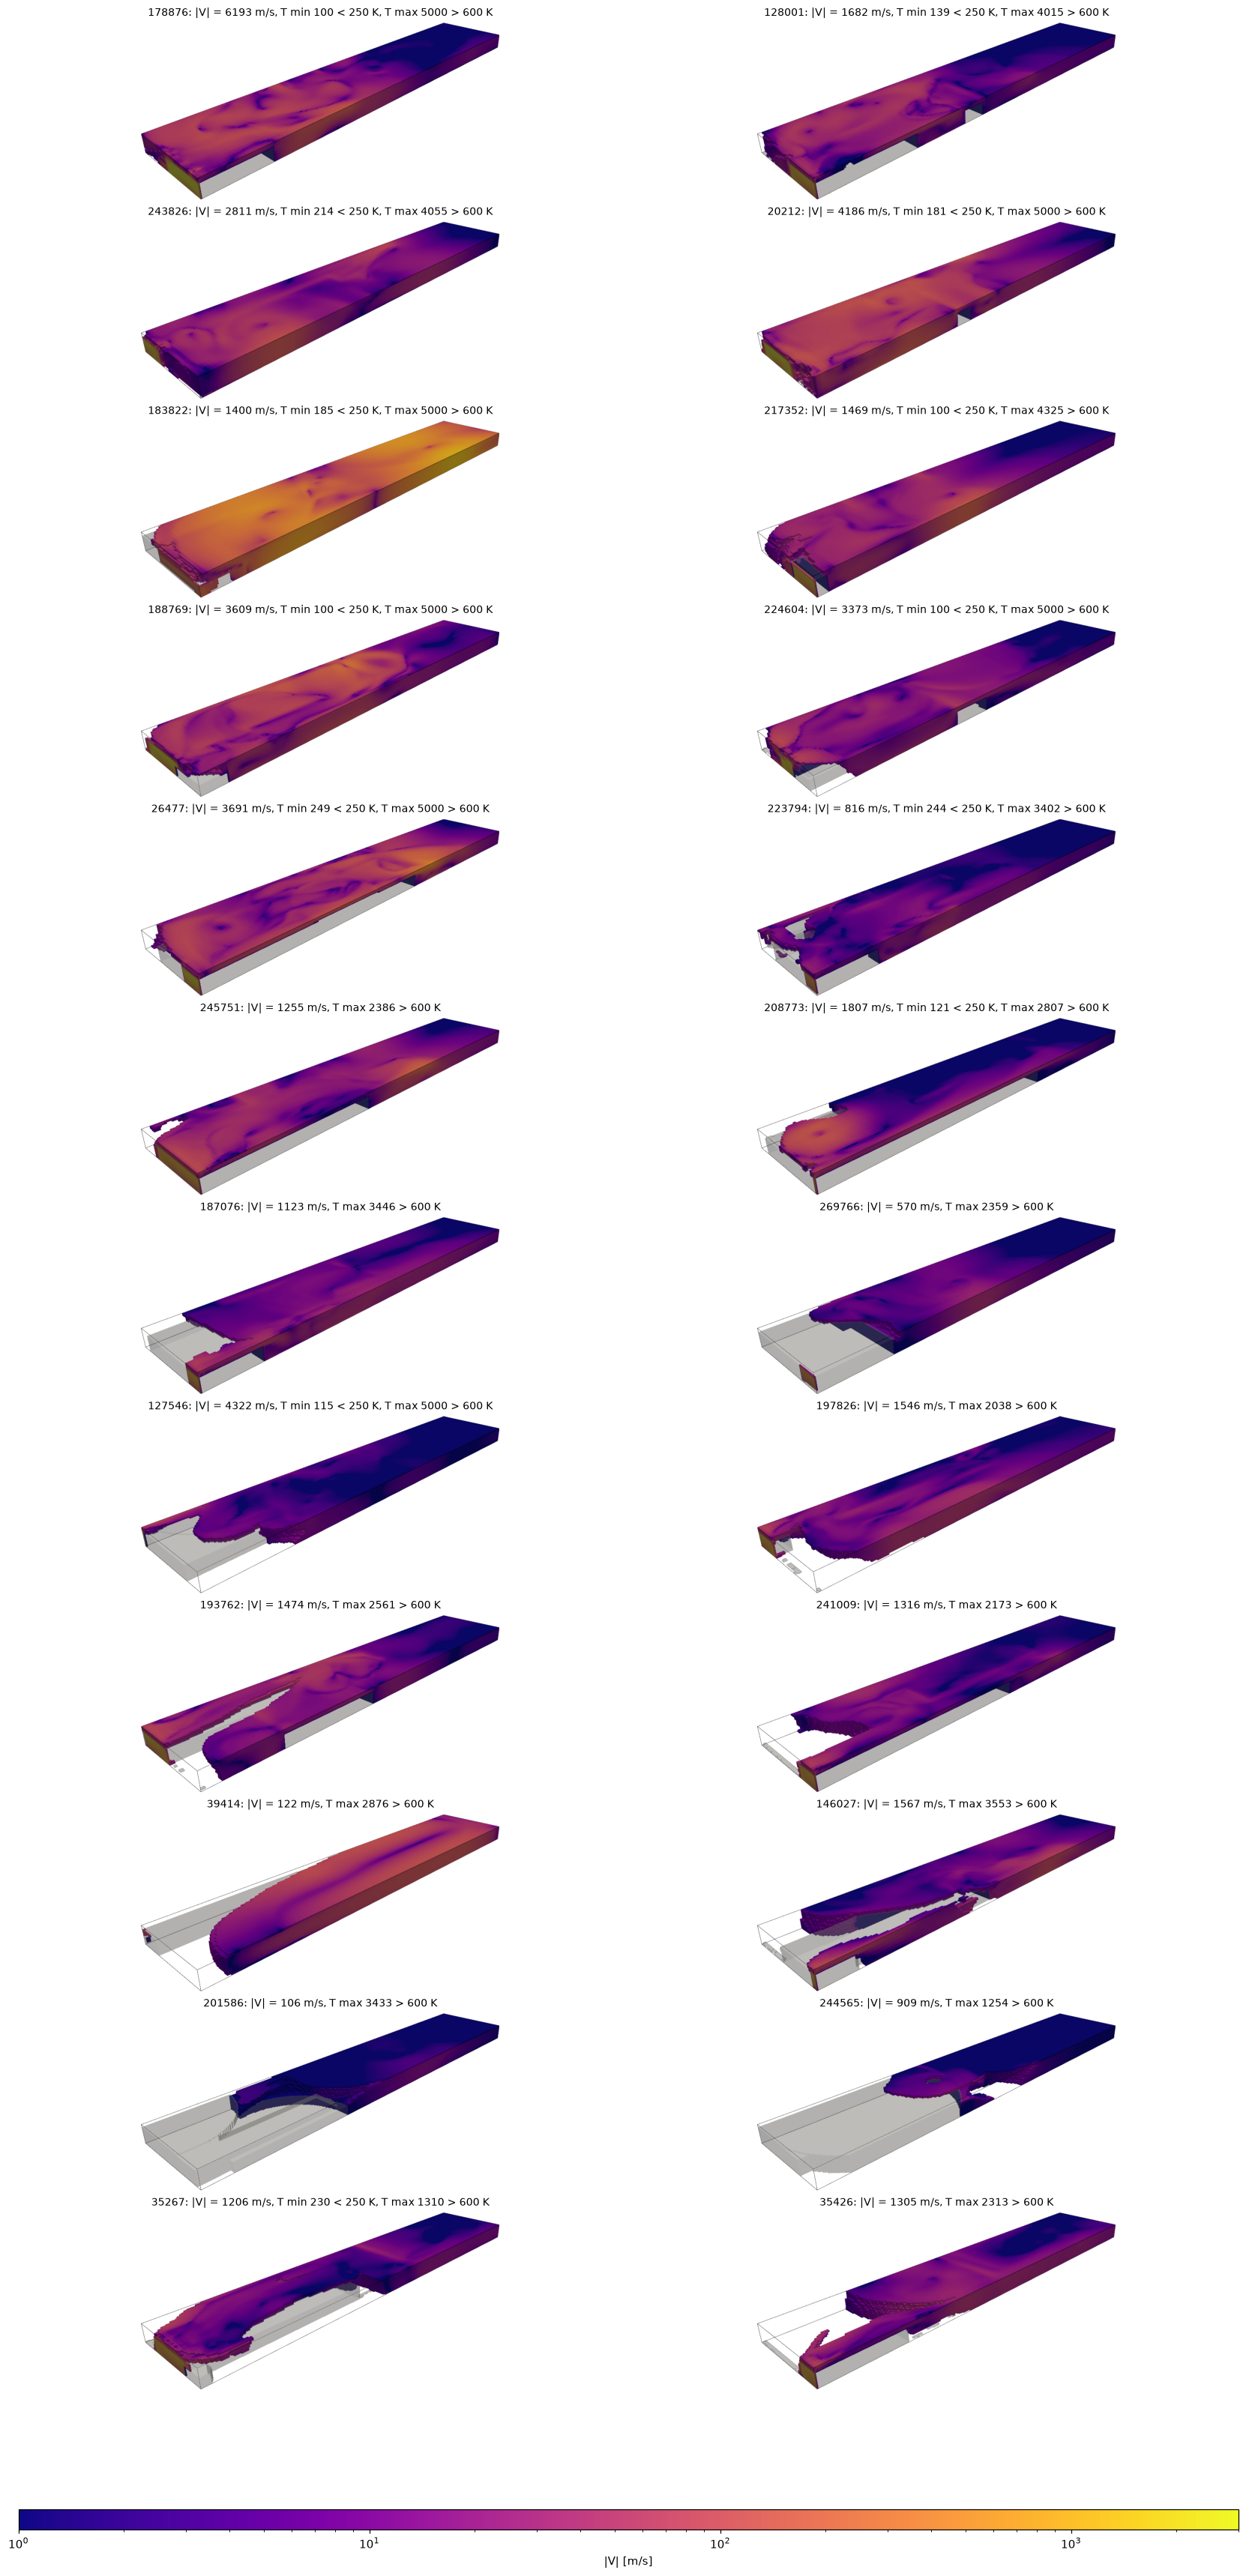

In [ ]:
GRID = Grid(latent_scale=1)  # 4M voxels per design at the sweep grid are too heavy to render
SPEED_LIMITS = (1.0, 3000.0)  # m/s, shared colour scale of all renders
N_RENDERED = 24  # largest rule-breaking shares first
rendered = outliers.head(N_RENDERED)
metadata = CoolMetadata.load(HOST_CONFIG.n_splits, HOST_CONFIG.idx_split).designs
dataset = CoolData(CoolMetadata(metadata.filter(pl.col("design_id").is_in(rendered["design_id"].to_list()))), DataConfig(grid=GRID))
fields_of = {int(flowfield.design_id): (flowfield.fields.numpy(), flowfield.mask.numpy()) for flowfield in map(dataset.__getitem__, range(len(dataset)))}


def render_rule_breaking_voxels(design: int) -> np.ndarray:
    """Off-screen 3D render of the solids and rule-breaking fluid voxels of `design`, RGB cropped to the content."""
    fields, fluid = fields_of[design]
    speed = np.linalg.norm(fields[:3], axis=0)
    temperature = fields[CHANNELS.index(Channel.TEMPERATURE)]
    breaks_rule = fluid & (
        (np.abs(fields[:3]).max(axis=0) > sweep.MAX_VELOCITY) | (temperature < sweep.TEMPERATURE_RANGE[0]) | (temperature > sweep.TEMPERATURE_RANGE[1])
    )
    image = pv.ImageData(dimensions=GRID.shape, spacing=GRID.spacing)
    for name, volume in (("solid", ~fluid), ("breaks_rule", breaks_rule), ("speed", np.where(fluid, speed, 0.0))):
        image.point_data[name] = volume.astype(np.float32).ravel(order="F")
    plotter = pv.Plotter(off_screen=True, window_size=(1400, 600))
    plotter.add_mesh(image.threshold(0.5, scalars="solid").extract_surface(algorithm="dataset_surface"), color=plots.SOLID_COLOR, opacity=0.3)
    if breaks_rule.any():  # none when the rule only breaks at the sweep grid
        plotter.add_mesh(
            image.threshold(0.5, scalars="breaks_rule"), scalars="speed", cmap="plasma", log_scale=True, clim=SPEED_LIMITS, show_scalar_bar=False
        )
    plotter.add_mesh(image.outline(), color="black")
    plotter.camera_position = [(-0.12, -0.28, 0.22), (0.24, 0.05, 0.0), (0.0, 0.0, 1.0)]
    rgb = plotter.screenshot(return_img=True)
    plotter.close()
    content_rows, content_columns = np.nonzero((rgb < 250).any(axis=-1))
    return rgb[content_rows.min() : content_rows.max() + 1, content_columns.min() : content_columns.max() + 1]


def short_reason(reason: str) -> str:
    """Compact outlier reason for plot titles."""
    return reason.replace("|V| ", "|V| = ").replace(" > 100 m/s", " m/s")


with pv.vtk_verbosity("off"):  # VTK warns about the missing X display, renders off-screen anyway
    renders = {design: render_rule_breaking_voxels(design) for design in rendered["design_id"]}
rows = (rendered.height + 1) // 2
figure, axes = plt.subplots(rows, 2, figsize=(15, 2.6 * rows), layout="constrained")
for axis, (design, reason) in zip(axes.flat, rendered.select("design_id", "reason").iter_rows(), strict=False):
    axis.imshow(renders[design])
    axis.set_title(f"{design}: {short_reason(reason)}", fontsize=9)
for axis in axes.flat:
    axis.axis("off")
figure.colorbar(
    plt.cm.ScalarMappable(norm=LogNorm(*SPEED_LIMITS), cmap="plasma"), ax=axes, orientation="horizontal", fraction=0.01, aspect=60, label="|V| [m/s]"
)
plt.show()

## 5. Distribution per channel

Share of fluid voxels per histogram bin, all designs in grey, curated designs in blue. The x axis is linear near zero
(near 293.15 K for T) and logarithmic beyond, so bulk and tails are both visible. Red lines: q0.001, median and q0.999
of the curated designs. Removing the 310 designs cuts off the far tails, the bulk is unchanged.

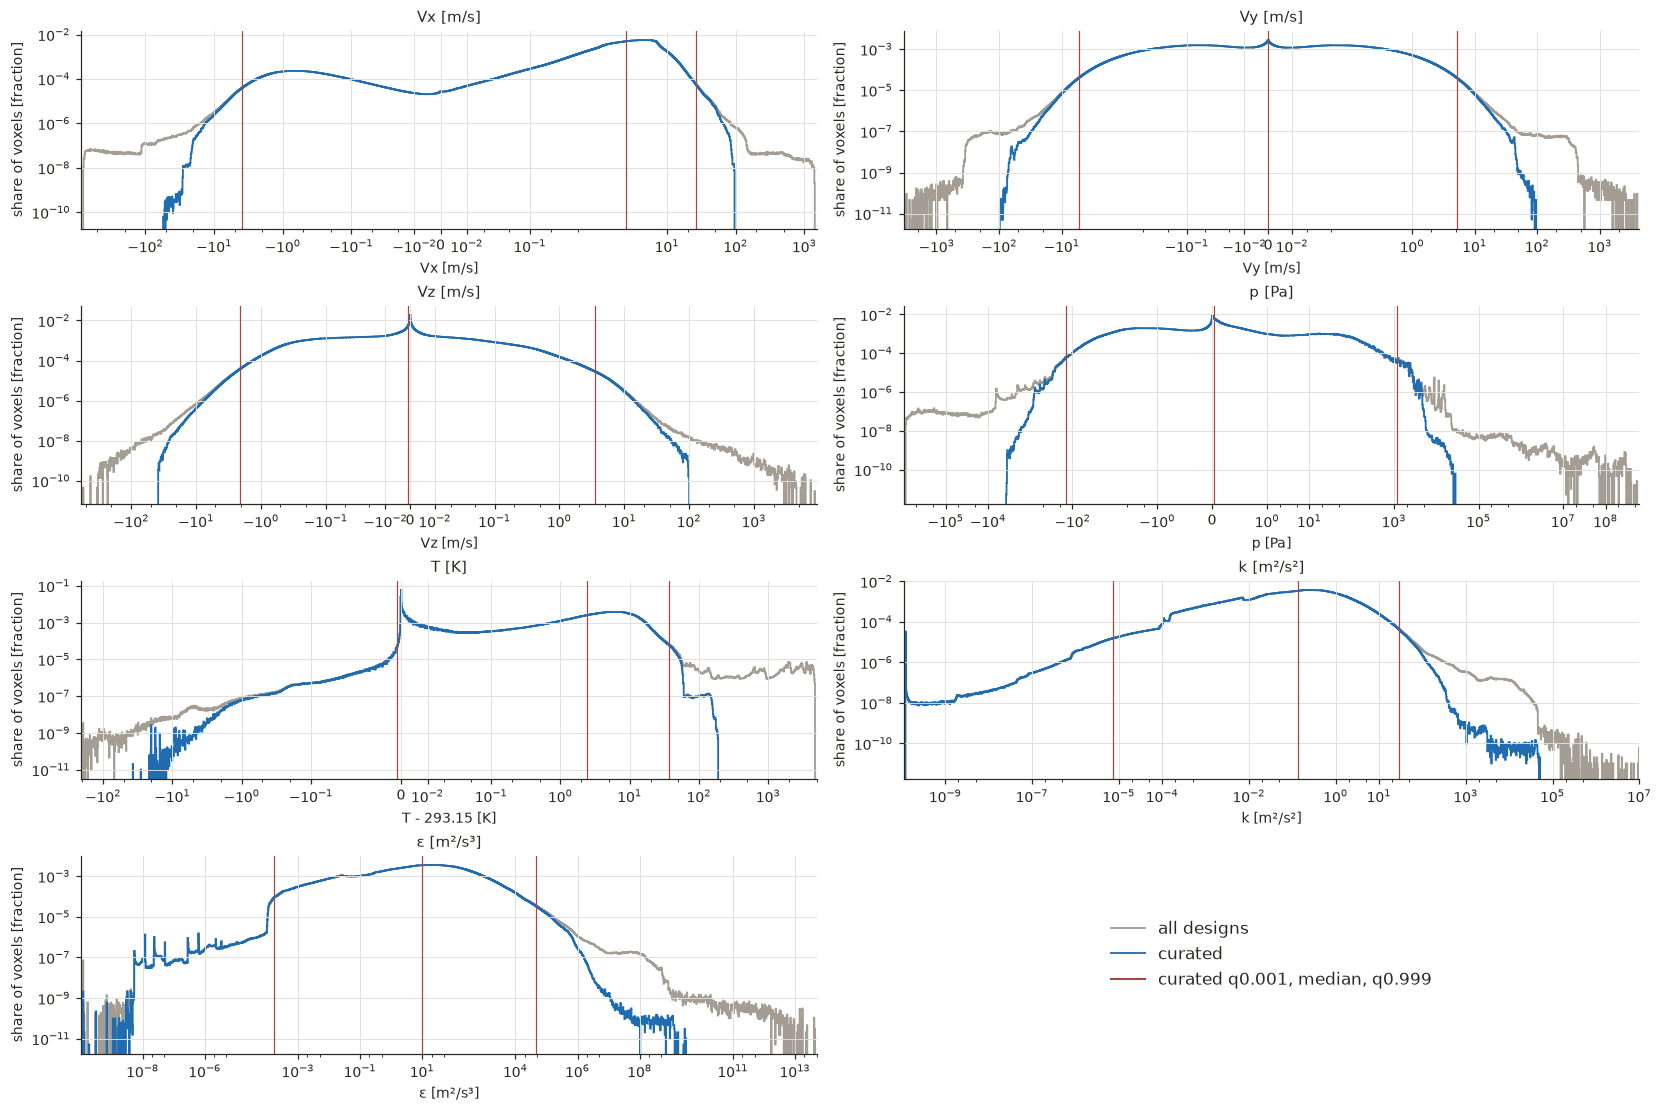

In [5]:
QUANTILE_LINES = (1e-3, 0.5, 0.999)
histogram_bins = pl.concat(
    pl.DataFrame(
        {
            "channel": symbol,
            "bin_low": histograms["bin_edges"][c, :-1],
            "bin_high": histograms["bin_edges"][c, 1:],
            "share_all": counts_all[c] / counts_all[c].sum(),
            "share_curated": counts_curated[c] / counts_curated[c].sum(),
        }
    )
    for c, symbol in enumerate(plots.CHANNEL_SYMBOLS)
)
curated_quantiles = pl.DataFrame(
    {
        "channel": np.repeat(plots.CHANNEL_SYMBOLS, len(QUANTILE_LINES)),
        "quantile": np.tile(QUANTILE_LINES, len(CHANNELS)),
        "value": sweep.histogram_quantiles(counts_curated, QUANTILE_LINES).ravel(),
    }
)
plots.value_histograms(histogram_bins, curated_quantiles, channel_axes)

## 6. Choosing the normalization

Three candidates on the curated designs, each maps quantile qlow → -1 and qhigh → 1, log10 first for k and ε, nothing
clipped. Narrow quantiles resolve the bulk better but push rare peaks further out, wide ones the opposite.

- **spread**: normalized width of the central 50 % of voxels (q0.25 to q0.75), larger resolves the bulk better
- **peak**: largest |normalized value| of any curated voxel, smaller keeps outliers closer to the training range
- **voxels beyond ±1**: share of curated voxels outside [-1, 1]

In [6]:
def candidate_stats(quantiles: tuple[float, float]) -> NormalizationStats:
    """Curated `quantiles` mapped to [-1, 1], log10 for `sweep.LOG_CHANNELS`, like `sweep.normalization_stats`."""
    low, high = torch.from_numpy(sweep.histogram_quantiles(counts_curated, quantiles)).float().T.reshape(2, -1, 1, 1, 1)
    is_log = torch.tensor([channel in sweep.LOG_CHANNELS for channel in CHANNELS]).view(-1, 1, 1, 1)
    linear = NormalizationStats(low=low, high=high, is_log=is_log, batch_size=[])
    return linear.replace(low=linear.transform(low), high=linear.transform(high))


def normalize(candidate: NormalizationStats, values: np.ndarray) -> np.ndarray:
    """(C, N) physical values -> normalized values under `candidate`."""
    transformed = candidate.transform(torch.from_numpy(values).float().reshape(len(CHANNELS), 1, 1, -1))
    return (2 * (transformed - candidate.low) / (candidate.high - candidate.low) - 1).reshape(values.shape).numpy()


CANDIDATES = ((1e-4, 0.9999), (1e-3, 0.999), (1e-2, 0.99))
curated_stats = design_stats.filter(~pl.col("design_id").is_in(excluded["design_id"].to_list())).group_by("channel", maintain_order=True)
curated_extremes = curated_stats.agg(pl.col("min").min(), pl.col("max").max()).select("min", "max").to_numpy().T  # (2, C)
quartiles = sweep.histogram_quantiles(counts_curated, (0.25, 0.75)).T  # (2, C)
spread_rows, peak_rows = [], []
for quantiles in CANDIDATES:
    candidate = candidate_stats(quantiles)
    label = f"{quantiles[0]:g} / {quantiles[1]:g}"
    spread = normalize(candidate, quartiles[1][:, None]) - normalize(candidate, quartiles[0][:, None])
    peak = np.abs(normalize(candidate, curated_extremes.T)).max(axis=1)
    beyond = (counts_curated * (np.abs(normalize(candidate, sweep.BIN_CENTERS)) > 1)).sum() / counts_curated.sum()
    spread_rows.append({"qlow / qhigh": label, "voxels beyond ±1 [%]": 100 * beyond, **dict(zip(CHANNEL_NAMES, spread[:, 0], strict=True))})
    peak_rows.append({"qlow / qhigh": label, **dict(zip(CHANNEL_NAMES, peak, strict=True))})
display(Markdown("**Spread** of the bulk, larger is better:\n\n" + markdown_table(pl.DataFrame(spread_rows))))
display(Markdown("**Peak** |normalized value|, smaller is better:\n\n" + markdown_table(pl.DataFrame(peak_rows))))

**Spread** of the bulk, larger is better:

| qlow / qhigh    | voxels beyond ±1 [%] | Vx [m/s] | Vy [m/s] | Vz [m/s] | p [Pa]   | T [K] | k [m²/s²] | ε [m²/s³] |
|-----------------|----------------------|----------|----------|----------|----------|-------|-----------|-----------|
| 0.0001 / 0.9999 | 0.0194               | 0.144    | 0.0114   | 0.00617  | 0.000932 | 0.236 | 0.325     | 0.399     |
| 0.001 / 0.999   | 0.197                | 0.253    | 0.0236   | 0.0147   | 0.00192  | 0.326 | 0.402     | 0.455     |
| 0.01 / 0.99     | 1.87                 | 0.478    | 0.0658   | 0.0515   | 0.00974  | 0.584 | 0.569     | 0.559     |

**Peak** |normalized value|, smaller is better:

| qlow / qhigh    | Vx [m/s] | Vy [m/s] | Vz [m/s] | p [Pa] | T [K] | k [m²/s²] | ε [m²/s³] |
|-----------------|----------|----------|----------|--------|-------|-----------|-----------|
| 0.0001 / 0.9999 | 2.91     | 8.95     | 14.6     | 19.5   | 6.35  | 1.91      | 2.19      |
| 0.001 / 0.999   | 5.62     | 18.5     | 35.2     | 40.9   | 9.16  | 2.47      | 2.47      |
| 0.01 / 0.99     | 11.2     | 51.5     | 125      | 211    | 17.2  | 3.68      | 2.99      |

**Choice: q0.001 / q0.999.** It roughly doubles the bulk spread of q0.0001 / q0.9999 and keeps every peak at 41 or
below, with 0.2 % of voxels beyond ±1. q0.01 / q0.99 resolves the bulk best but puts Vz and p voxels at 125 and 211:
under an MSE loss, one such voxel outweighs about 10⁴ bulk voxels.

The bulk of Vy, Vz and p stays narrow under every choice (spread ≤ 0.066): most of the fluid is nearly at rest, and a
few jets and pressure peaks set the scale.

Below: the curated voxel density under the chosen normalization. Most voxels fall inside ±1 (red), the tails reach
out to the peaks above.

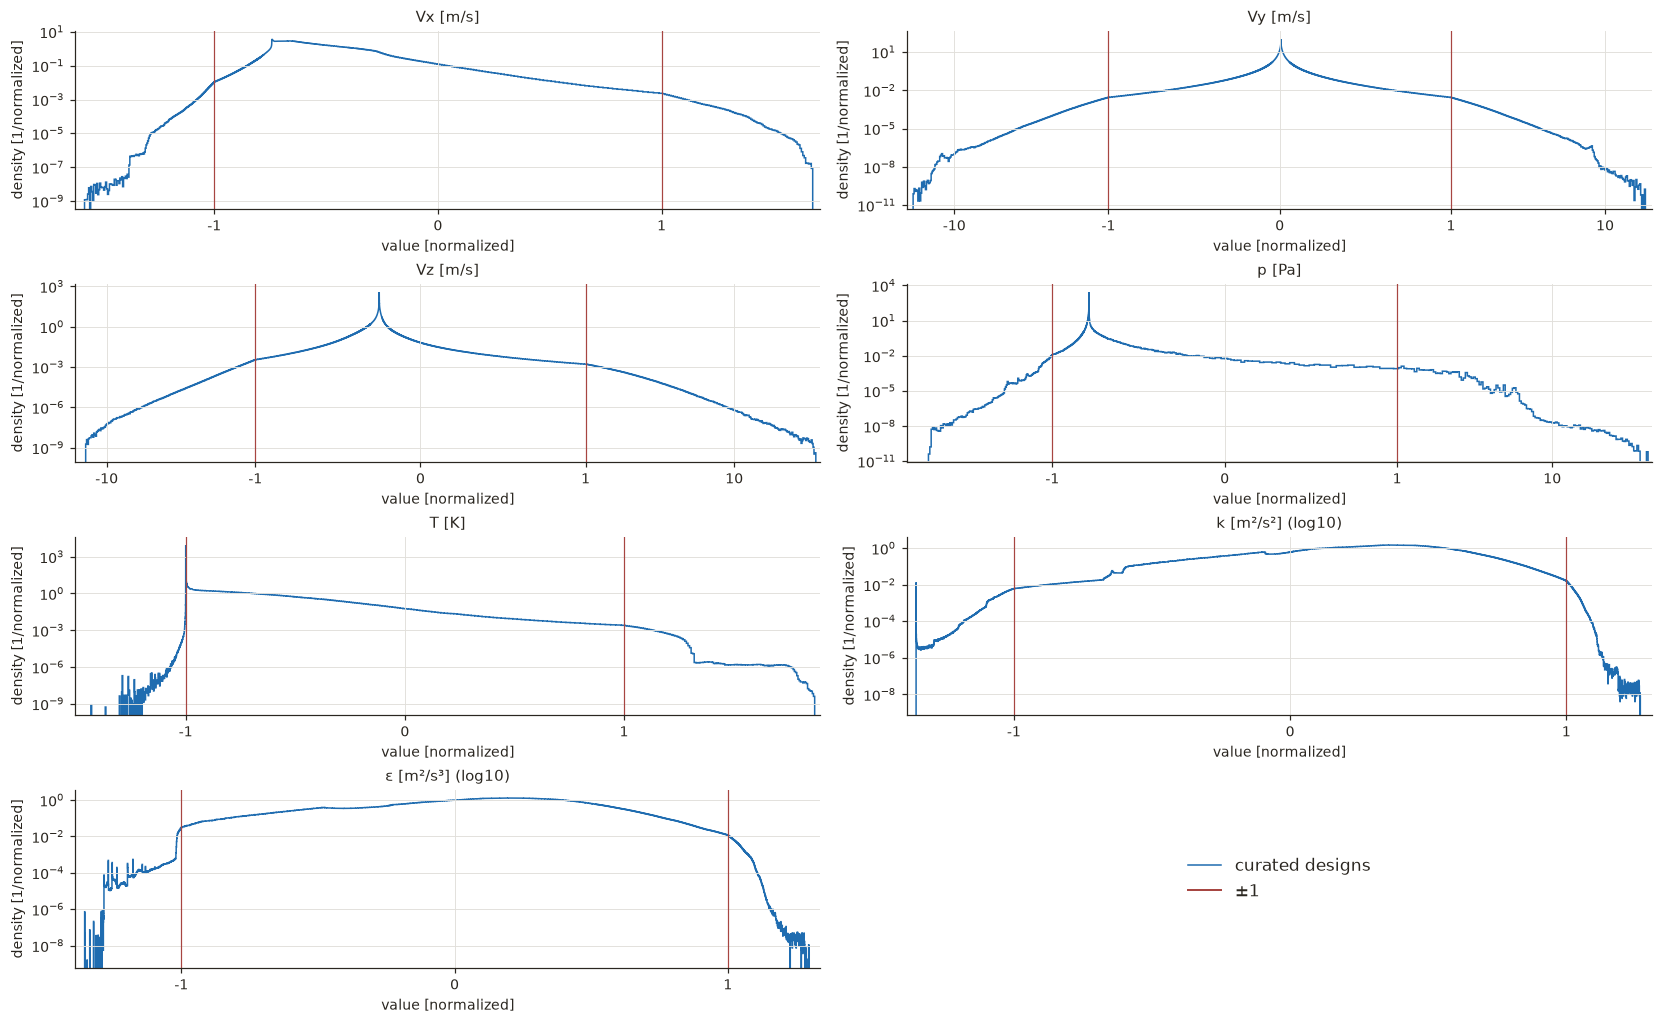

In [7]:
normalized_edges = normalize(stats, histograms["bin_edges"])
normalized_bins = pl.concat(
    pl.DataFrame(
        {
            "channel": symbol,
            "bin_low": normalized_edges[c, :-1],
            "bin_high": normalized_edges[c, 1:],
            "share": counts_curated[c] / counts_curated[c].sum(),
        }
    )
    for c, symbol in enumerate(plots.CHANNEL_SYMBOLS)
)
plots.normalized_density(normalized_bins, channel_axes)

## Conclusion

- Exclude the 310 flagged designs (0.5 % of the data) as physically implausible, likely diverged simulations.
- Put k and ε on a log10 scale, they span 8 to 10 decades between q0.0001 and q0.9999 of the curated designs.
- Normalize every channel with q0.001 → -1 and q0.999 → 1 of the curated designs, without clipping.
- Training on every host uses this normalization and exclusion list, from
  [`results/normalization_stats.csv`](../experiments/01_cooldata-value-distribution/results/normalization_stats.csv)
  and [`results/excluded_designs.csv`](../experiments/01_cooldata-value-distribution/results/excluded_designs.csv).

**Open question:** MSE in log10 space weighs relative errors of k and ε in quiescent regions as much as in turbulent
ones. Keep it, or weight the loss?